# Deliverables 5

#### All Imports:

In [4]:
import requests
import os
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

#### Query the API for the latitude/longitude pairs in the AirBnB dataset to obtain the area codes matching the bond dataset.

In [8]:
#Before doing query on all co-ordinates, need to check with one data first
url = "https://koordinates.com/services/query/v1/vector.json"
params = {
    "key": "c7db3ab9d89946fea70d38d1fb3f46ef",
    "layer": 123515,
    "x": 172.6,
    "y": -43.5,
    "max_results": 1
}

# user-agent header
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

response = requests.get(url, params=params, headers=headers)

# HTTP status code
print("Status Code:", response.status_code)

if response.status_code == 200:
    data = response.json()
    print("Success! JSON Output:\n", data)
else:
    print("Server returned non-200 response:\n", response.text[:500])

Status Code: 200
Success! JSON Output:
 {'vectorQuery': {'layers': {'123515': {'type': 'FeatureCollection', 'crs': {'type': 'name', 'properties': {'name': 'EPSG:4326'}}, 'features': [{'type': 'Feature', 'properties': {'SA22026_V1_00': '320800', 'SA22026_V1_00_NAME': 'Bryndwr South', 'SA22026_V1_00_NAME_ASCII': 'Bryndwr South', 'LAND_AREA_SQ_KM': 0.90574671, 'AREA_SQ_KM': 0.90574671, 'Shape_Length': 5168.510596271917, 'Shape_Area': 905746.7374725485}, 'distance': 0, 'id': 4500}]}}}}


In [76]:
DATA_DIR = pathlib.Path(r"data")
OUTPUT_DIR = DATA_DIR / "airbnb_sa2"

# create the new airbnb_sa2 directory
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = DATA_DIR / "christchurch_listings_cleaned.csv"
OUTPUT_FILE = OUTPUT_DIR / "christchurch_listings_with_sa2.csv"

# API Configuration
API_KEY = "c7db3ab9d89946fea70d38d1fb3f46ef"
LAYER_ID = 123515
BASE_URL = "https://koordinates.com/services/query/v1/vector.json"
MAX_WORKERS = 10  # Number of parallel requests

# load Data
print(f"Loading '{INPUT_FILE}'...")
df = pd.read_csv(INPUT_FILE)
print(f"Total rows loaded: {len(df):,}")

# extract unique coordinates
unique_coords = df[["latitude", "longitude"]].drop_duplicates().dropna().values.tolist()
print(f"Unique coordinate pairs to query: {len(unique_coords):,}")

# define API query function (ID and name)
def fetch_sa2_details(coord):
    lat, lon = coord
    params = {
        "key": API_KEY,
        "layer": LAYER_ID,
        "x": lon,
        "y": lat,
        "max_results": 1
    }
    headers = {"User-Agent": "Mozilla/5.0"}
    
    try:
        response = requests.get(BASE_URL, params=params, headers=headers, timeout=10)
        if response.status_code == 200:
            data = response.json()
            features = (
                data.get("vectorQuery", {})
                .get("layers", {})
                .get(str(LAYER_ID), {})
                .get("features", [])
            )
            if features:
                props = features[0].get("properties", {})
                sa2_code = props.get("SA22026_V1_00")
                sa2_name = props.get("SA22026_V1_00_NAME")
                return (lat, lon, str(sa2_code) if sa2_code else None, str(sa2_name) if sa2_name else None)
    except Exception:
        pass
        
    return (lat, lon, None, None)

# execute all queries
coord_map = {}
print("\nQuerying Koordinates API in parallel for location_id and location_name...")

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(fetch_sa2_details, coord) for coord in unique_coords]
    
    for future in tqdm(as_completed(futures), total=len(futures), desc="Progress"):
        lat, lon, sa2_code, sa2_name = future.result()
        coord_map[(lat, lon)] = (sa2_code, sa2_name)

# map location_id and location_name back to Full Dataset
df["location_id"] = df.apply(lambda row: coord_map.get((row["latitude"], row["longitude"]), (None, None))[0], axis=1)
df["location_name"] = df.apply(lambda row: coord_map.get((row["latitude"], row["longitude"]), (None, None))[1], axis=1)

# save Updated File
df.to_csv(OUTPUT_FILE, index=False)

print("\n--- Process Complete ---")
print(f"Total records saved: {len(df):,}")
print(f"Successfully assigned location_id: {df['location_id'].notna().sum():,}")
print(f"Successfully assigned location_name: {df['location_name'].notna().sum():,}")
print(f"Saved file to: {OUTPUT_FILE}")

Loading 'data\christchurch_listings_cleaned.csv'...
Total rows loaded: 28,795
Unique coordinate pairs to query: 3,957

Querying Koordinates API in parallel for location_id and location_name...


Progress: 100%|██████████| 3957/3957 [10:40<00:00,  6.17it/s]



--- Process Complete ---
Total records saved: 28,795
Successfully assigned location_id: 28,795
Successfully assigned location_name: 28,795
Saved file to: data\airbnb_sa2\christchurch_listings_with_sa2.csv


#### Inspecting the new file, see missing values and deal with it

In [5]:
file_path = pathlib.Path(r"data\airbnb_sa2\christchurch_listings_with_sa2.csv")

df = pd.read_csv(file_path)
df.head()

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,number_of_reviews_ltm,month_year,location_id,location_name
0,319770,Gateway to the South Island,1639584.0,Jennifer,Innes Ward,-43.50961,172.65552,Private room,196.0,1.0,3,1.0,364,0,April 2026,325900,Richmond North (Christchurch City)
1,737452,Mumfords Akaroa,3851282.0,Nicky,Banks Peninsula Ward,-43.82343,172.94643,Entire home/apt,394.0,2.0,102,1.0,194,3,April 2026,333300,Akaroa Harbour
2,1004252,Governors Bay Waterfront Retreat,5523780.0,Rosie,Banks Peninsula Ward,-43.61889,172.65314,Entire home/apt,183.0,2.0,227,1.0,173,10,April 2026,332200,Governors Bay
3,1007247,Clarence Cottage,4765250.0,John,Riccarton Ward,-43.53955,172.60697,Entire home/apt,305.0,2.0,119,1.0,304,5,April 2026,325500,Tower Junction
4,1097487,Heritage Magic in Merivale,4993285.0,Paulette,Fendalton Ward,-43.51149,172.62540,Private room,189.0,1.0,230,1.0,295,0,April 2026,322200,Rutland


In [6]:
df[
    [
        "id",
        "name",
        "latitude",
        "longitude",
        "location_id",
        "location_name",
        "month_year",
    ]
].head(10)

,id,name,latitude,longitude,location_id,location_name,month_year
0,319770,Gateway to the South Island,-43.509610,172.655520,325900,Richmond North (Christchurch City),April 2026
1,737452,Mumfords Akaroa,-43.823430,172.946430,333300,Akaroa Harbour,April 2026
2,1004252,Governors Bay Waterfront Retreat,-43.618890,172.653140,332200,Governors Bay,April 2026
3,1007247,Clarence Cottage,-43.539550,172.606970,325500,Tower Junction,April 2026
4,1097487,Heritage Magic in Merivale,-43.511490,172.625400,322200,Rutland,April 2026
5,1429281,Self contained & fully equipped,-43.569820,172.552290,324300,Oaklands West,April 2026
6,1461771,Mt Pleasant - Retro Living apartment,-43.558130,172.720250,332000,Mount Pleasant,April 2026
7,1798383,"3 private rooms up to 6 guests, spacious modern.",-43.469002,172.664337,321301,Prestons,April 2026
8,1837611,"Close to University, 10 mins from Airport and ...",-43.513320,172.578400,320600,Jellie Park,April 2026
9,1893596,"Luxury at its best, Quail's Nest",-43.627280,172.718720,332901,Diamond Harbour,April 2026


In [7]:
# Summary of all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28795 entries, 0 to 28794
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              28795 non-null  int64  
 1   name                            28795 non-null  object 
 2   host_id                         28795 non-null  float64
 3   host_name                       28794 non-null  object 
 4   neighbourhood                   28795 non-null  object 
 5   latitude                        28795 non-null  float64
 6   longitude                       28795 non-null  float64
 7   room_type                       28795 non-null  object 
 8   price                           18128 non-null  float64
 9   minimum_nights                  28758 non-null  float64
 10  number_of_reviews               28795 non-null  int64  
 11  calculated_host_listings_count  28795 non-null  float64
 12  availability_365                

In [8]:
# Count of missing values in each column
print(f"Missing Values Count: ")
df.isna().sum()

Missing Values Count: 


id                                    0
name                                  0
host_id                               0
host_name                             1
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                             10667
minimum_nights                       37
number_of_reviews                     0
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
month_year                            0
location_id                           0
location_name                         0
dtype: int64

#### Cleaning the bond dataset (226,080 rows, nationwide) before merging. Filtering to Christchurch only using Airbnb listings as reference filter.

In [82]:
DATA_DIR = pathlib.Path(r"data")
AIRBNB_FILE = DATA_DIR / "airbnb_sa2" / "christchurch_listings_with_sa2.csv"
BOND_FILE = DATA_DIR / "Detailed-Quarterly-Tenancy-Q1-2020-Q3-2026.csv"
OUTPUT_BOND_CHCH = DATA_DIR / "rental_bond_christchurch_filtered.csv"

# datasets
df_airbnb = pd.read_csv(AIRBNB_FILE)
df_bond = pd.read_csv(BOND_FILE)

# clean Location IDs in Airbnb to act as our Christchurch reference filter
df_airbnb["location_id_key"] = (
    df_airbnb["location_id"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True)
)

# extract unique Christchurch location keys
chch_location_ids = df_airbnb["location_id_key"].unique()

# clean Location IDs in the Nationwide Bond Dataset
df_bond["location_id_key"] = (
    df_bond["Location Id"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True)
)

# filter Bond Dataset strictly for Christchurch locations
df_bond_chch = df_bond[df_bond["location_id_key"].isin(chch_location_ids)]

# saved the filtered Christchurch bond dataset with the new filename
df_bond_chch.to_csv(OUTPUT_BOND_CHCH, index=False)

print("--- Christchurch Bond Filtering Complete ---")
print(f"Original Nationwide Bond rows: {len(df_bond):,}")
print(f"Filtered Christchurch from Bond dataset: {len(df_bond_chch):,}")
print(f"Saved file to: {OUTPUT_BOND_CHCH}")

--- Christchurch Bond Filtering Complete ---
Original Nationwide Bond rows: 226,080
Filtered Christchurch from Bond dataset: 18,631
Saved file to: data\rental_bond_christchurch_filtered.csv


### Merging Time!!!

In [84]:
# file merge
DATA_DIR = pathlib.Path(r"data")
AIRBNB_FILE = DATA_DIR / "airbnb_sa2" / "christchurch_listings_with_sa2.csv"
BOND_CHCH_FILTERED_FILE = DATA_DIR / "rental_bond_christchurch_filtered.csv"
FINAL_MERGED_OUTPUT = DATA_DIR / "airbnb_sa2" / "chch_listings_rental_bond_with_sa2_merged.csv"

# load the Clean Christchurch Datasets
print("Loading Christchurch Airbnb and filtered bond datasets...")
df_airbnb = pd.read_csv(AIRBNB_FILE)
df_bond_chch = pd.read_csv(BOND_CHCH_FILTERED_FILE)

# added new columns for my understanding, these columns will be removed later
df_airbnb["join_timeframe_key"] = (
    pd.to_datetime(df_airbnb["month_year"], format="%B %Y")
    .dt.to_period("Q")
    .dt.start_time.dt.strftime("%Y-%m-%d")
)
df_airbnb["join_location_key"] = (
    df_airbnb["location_id"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True)
)

df_bond_chch["join_location_key"] = (
    df_bond_chch["Location Id"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True)
)

# execute merge
print("Executing merge")
df_christchurch_merged = pd.merge(
    df_airbnb,
    df_bond_chch,
    left_on=["join_location_key", "join_timeframe_key"],
    right_on=["join_location_key", "TimeFrame"],
    how="inner",
)

# save new dataset to the airbnb_sa2 directory
df_christchurch_merged.to_csv(FINAL_MERGED_OUTPUT, index=False)

print("--- Merge Complete ---")
print(f"Merged dataset rows: {len(df_christchurch_merged):,}")
print(f"Saved successfully to: {FINAL_MERGED_OUTPUT}")

Loading Christchurch Airbnb and filtered bond datasets...
Executing merge
--- Merge Complete ---
Merged dataset rows: 190,094
Saved successfully to: data\airbnb_sa2\chch_listings_rental_bond_with_sa2_merged.csv


#### Checking new merge file

In [85]:
#dropping unnecessary columns
path = r"data\airbnb_sa2\chch_listings_rental_bond_with_sa2_merged.csv"

df = pd.read_csv(path)
df = df.drop(
    columns=[
        "join_timeframe_key",
        "join_location_key",
        "location_id_key",
        "Location Id",
    ],
    errors="ignore",
)
df.to_csv(path, index=False)

In [86]:
#checking missing values in the new merge file
df = pd.read_csv(r"data\airbnb_sa2\chch_listings_rental_bond_with_sa2_merged.csv")
df.isna().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                             71312
minimum_nights                      333
number_of_reviews                     0
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
month_year                            0
location_id                           0
location_name                         0
TimeFrame                             0
Dwelling Type                         0
Number Of Beds                     8397
Total Bonds                           0
Active Bonds                          0
Closed Bonds                          0
Median Rent                           0
Geometric Mean Rent                   0


### Calculate median price of Christchurch Central (location id=326600)

In [89]:
central_df = df[df["location_id"] == 326600]
median_price = central_df["price"].median()

print(f"Median Airbnb Price in Christchurch Central: {median_price}")

Median Airbnb Price in Christchurch Central: 253.0


### Largest gap between short and long term rental prices across Christchurch

In [90]:
# the merged file and the geographic concordance table
df = pd.read_csv(r"data\airbnb_sa2\chch_listings_rental_bond_with_sa2_merged.csv")
geo_path = r"data\statsnz geographic areas table\geographic-areas-table-2023.csv"
df_geo = pd.read_csv(geo_path)

# unique mapping between SA2 code and Ward/SA2 names
geo_lookup = df_geo[
    ["SA22023_code", "SA22023_name", "WARD2023_name"]
].drop_duplicates()

# merged them together to create an analysis of the objective, did not save the file.
df_analysis = df.merge(geo_lookup, left_on="location_id", right_on="SA22023_code", how="left")

# calculated daily price gap
df_analysis["long_term_daily_rent"] = df_analysis["Median Rent"] / 7
df_analysis["price_gap_per_night"] = (
    df_analysis["price"] - df_analysis["long_term_daily_rent"]
)

# aggregate and display top gap locations (SA2 level)
sa2_summary = (
    df_analysis.groupby(["location_id", "location_name"])[
        "price_gap_per_night"
    ]
    .agg(
        median_gap="median",
        mean_gap="mean",
        max_gap="max",
        listing_count="count",
    )
    .sort_values(by="median_gap", ascending=False)
)

print("--- Top 10 SA2 Locations with Largest Price Gap ---")
print(sa2_summary.head(10))

--- Top 10 SA2 Locations with Largest Price Gap ---
                                  median_gap    mean_gap       max_gap  \
location_id location_name                                                
322800      Wigram West           243.642857  243.971429    325.000000   
322600      Holmwood              209.071429  242.471624    955.142857   
324200      Riccarton Central     204.714286  241.047619    470.714286   
332700      Sumner                201.142857  302.070428   1830.428571   
317400      Northwood             193.000000  346.334416   1099.000000   
330500      Ensors                187.000000  221.334172    659.285714   
322100      Malvern               182.571429  203.468005    853.571429   
328800      Lancaster Park        180.142857  202.428571    386.142857   
322300      Sockburn South        175.285714  176.904762    194.428571   
326600      Christchurch Central  174.428571  323.281139  43581.428571   

                                  listing_count  
location_

#### Aggregate and Display by Ward (Pooled suburbs into larger areas)

In [91]:
# aggregate and display by Ward area (Pooled level)
ward_summary = (
    df_analysis.groupby("WARD2023_name")["price_gap_per_night"]
    .agg(
        median_gap="median",
        mean_gap="mean",
        max_gap="max",
        listing_count="count",
    )
    .sort_values(by="median_gap", ascending=False)
)

print("\nPrice Gap Aggregated by Ward:")
print(ward_summary)


Price Gap Aggregated by Ward:
                median_gap    mean_gap       max_gap  listing_count
WARD2023_name                                                      
Central Ward    146.142857  173.401064  43581.428571          62825
Innes Ward      135.428571  166.603376   1367.857143           9453
Fendalton Ward  131.142857  167.528959   1736.428571          11911
Halswell Ward   112.714286  143.030886   1060.142857           1864
Heathcote Ward  106.428571  168.463360   2362.857143           8451
Riccarton Ward  106.428571  131.099653   1138.428571          10862
Spreydon Ward   105.428571  130.505861   2154.428571           7203
Coastal Ward     92.928571  108.508939   1139.714286           3308
Hornby Ward      92.142857  141.477279   1998.571429           2012
Cashmere Ward    69.285714  138.510556   2950.428571           3769
Waimairi Ward    66.857143   94.221622    840.714286           4547
Papanui Ward     62.857143  123.666401    944.428571           3052
Linwood Ward     

##### Visual by Ward

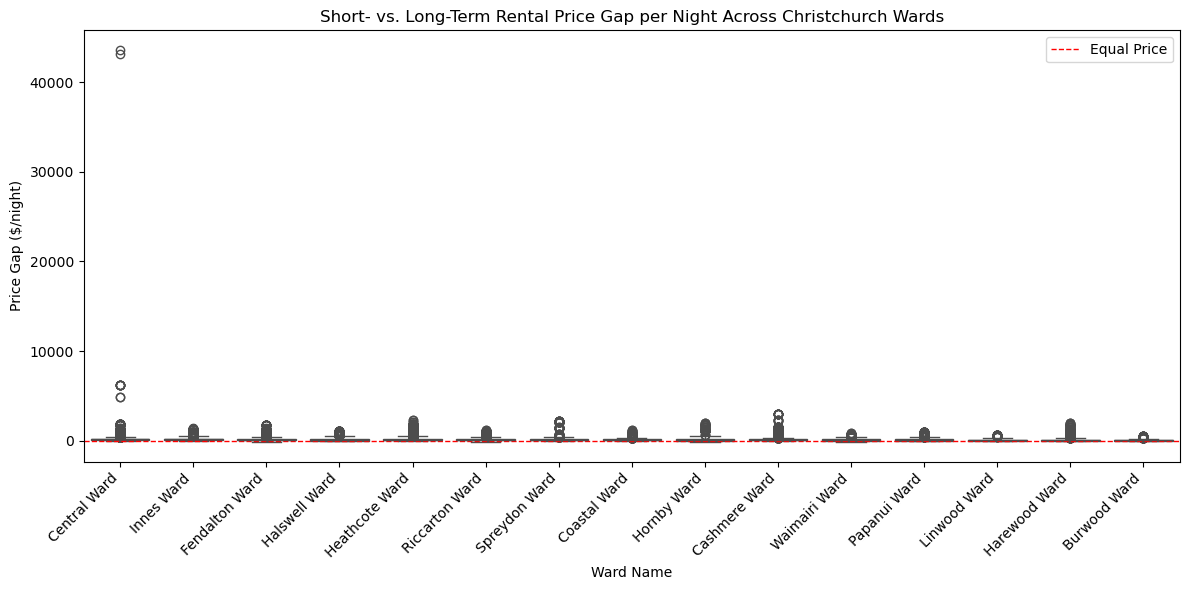

In [96]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_analysis,
    x="WARD2023_name",
    y="price_gap_per_night",
    order=ward_summary.index,
    palette="coolwarm",
)

plt.xticks(rotation=45, ha="right")
plt.axhline(0, color="red", linestyle="--", linewidth=1, label="Equal Price")
plt.title(
    "Short- vs. Long-Term Rental Price Gap per Night Across Christchurch Wards"
)
plt.xlabel("Ward Name")
plt.ylabel("Price Gap ($/night)")
plt.legend()
plt.tight_layout()
plt.show()

**The graph squished 99% of the actual data because of the extreme outliers (example: Central Ward: $43581.4 max_gap) that forced the Y axis all the way upto 40,000+.**

#### Correcting above code and Handling extreme outliers and visualizing again

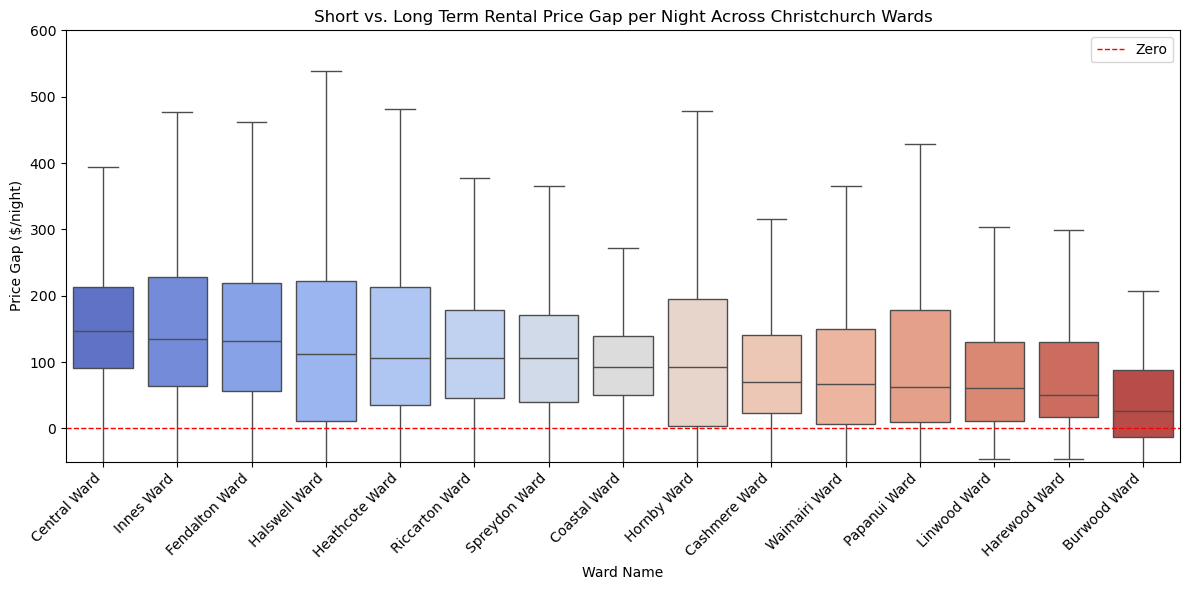

In [94]:
ward_order = (
    df_analysis.groupby("WARD2023_name")["price_gap_per_night"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_analysis,
    x="WARD2023_name",
    y="price_gap_per_night",
    order=ward_order,
    palette="coolwarm",
    showfliers=False,  # excluding extreme outliers to prevent squishing
)

plt.xticks(rotation=45, ha="right")
plt.ylim(-50, 600)  # focus Y-axis on readable range
plt.axhline(0, color="red", linestyle="--", linewidth=1, label="Zero")
plt.title("Short vs. Long Term Rental Price Gap per Night Across Christchurch Wards")
plt.xlabel("Ward Name")
plt.ylabel("Price Gap ($/night)")
plt.legend()
plt.tight_layout()
plt.show()

#### Findings:

* **Central Ward** has the highest median price gap overall (\$146/night) across broader geographical areas.
* **Innes Ward** (\$135.43/night) and **Fendalton Ward** (\$131.14/night) have the broadest interquartile ranges (tall height with blue boxes). This shows significant spread in short-term rental pricing within those districts.
* **Burwood Ward** sits at the bottom with the lowest median price gap of $25.57/night. It indicates that short-term and long-term rentals are closest to parity in this area.
* Every single ward maintains a median price gap above zero (*the red dashed line*). This demonstrates that the short-term rent yield a much better daily price over long-term rent across the entire city.

#### Visualize by Suburbs (using location_name)

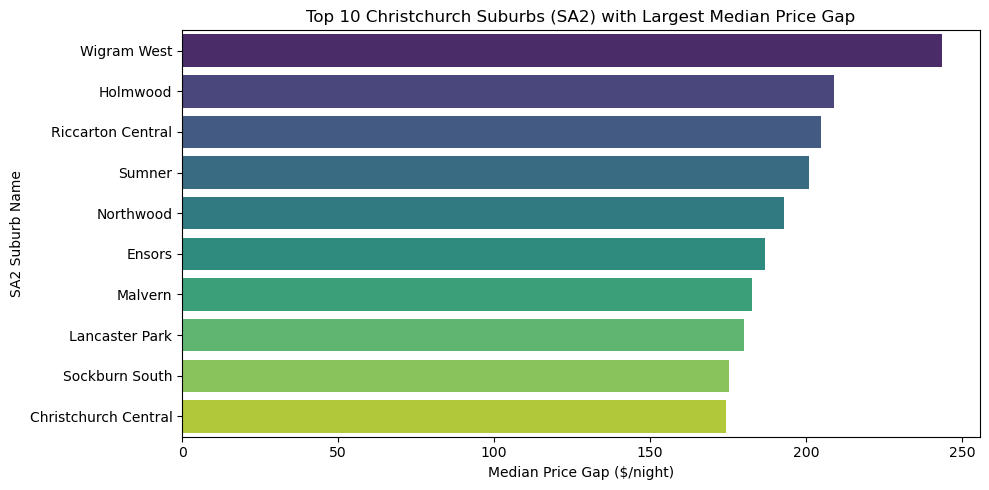

In [97]:
top_sa2 = (
    df_analysis.groupby("location_name")["price_gap_per_night"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_sa2, x="price_gap_per_night", y="location_name", palette="viridis"
)
plt.title("Top 10 Christchurch Suburbs (SA2) with Largest Median Price Gap")
plt.xlabel("Median Price Gap ($/night)")
plt.ylabel("SA2 Suburb Name")
plt.tight_layout()
plt.show()

#### Findings:

* **Wigram West** stands out as the location with the absolute largest median price gap, where short-term rent exceeds daily long-term rent by **\$243.64/night**.
* **Holmwood** (\$209.07/night) and **Riccarton Central** (\$204.71/night), in second and third place, maintained median price gaps above **\$200/night**.
* Suburbs such as **Sumner** (\$201.14/night), **Northwood**, **Ensors**, **Malvern**, **Lancaster Park**, **Sockburn South**, and **Christchurch Central** round out the top 10 all showing strong premium spreads for short-term over long-term rent.

### How many AirBnBs and rental properties we have in each location?

In [106]:
#load the merged dataset
df_merged = pd.read_csv(r"data\airbnb_sa2\chch_listings_rental_bond_with_sa2_merged.csv"
)
#analyzing how many locations there are
total_locations = df_merged["location_name"].nunique()
print(f"Total locations: {total_locations}")

Total locations: 122


#### Filtering for total summary rows to avoid overcounting (the 'ALL' value) and showing Top 15 locations

In [107]:
# using 'ALL' dwelling type & bed breakdowns to get total active long-term bonds
df_totals = df_merged[
    (df_merged["Dwelling Type"] == "ALL")
    & (df_merged["Number Of Beds"] == "ALL")
]

# calculate counts per location_name
location_counts = (
    df_totals.groupby("location_name")
    .agg(
        airbnb_property_count=("id", "nunique"),  # Unique AirBnB listings
        rental_property_count=(
            "Active Bonds",
            "max",
        ),  # Actual active long-term tenancy bonds
    )
    .reset_index()
    .sort_values(by="airbnb_property_count", ascending=False)
)

print("Property Comparison by Location (Top 15) ")
print(location_counts.head(15))

Property Comparison by Location (Top 15) 
                  location_name  airbnb_property_count  rental_property_count
28    Christchurch Central-East                    402                    987
30   Christchurch Central-South                    312                    276
29   Christchurch Central-North                    220                   1134
27         Christchurch Central                    153                     42
31    Christchurch Central-West                    142                    453
101                      Sumner                     79                    270
57                     Merivale                     79                    654
96               St Albans East                     62                   1026
98               St Albans West                     61                    711
61                 New Brighton                     54                    480
113                    Wharenui                     49                    549
81              Riccar

#### Comparison of AirBnB vs. Rental Properties by Location visuals

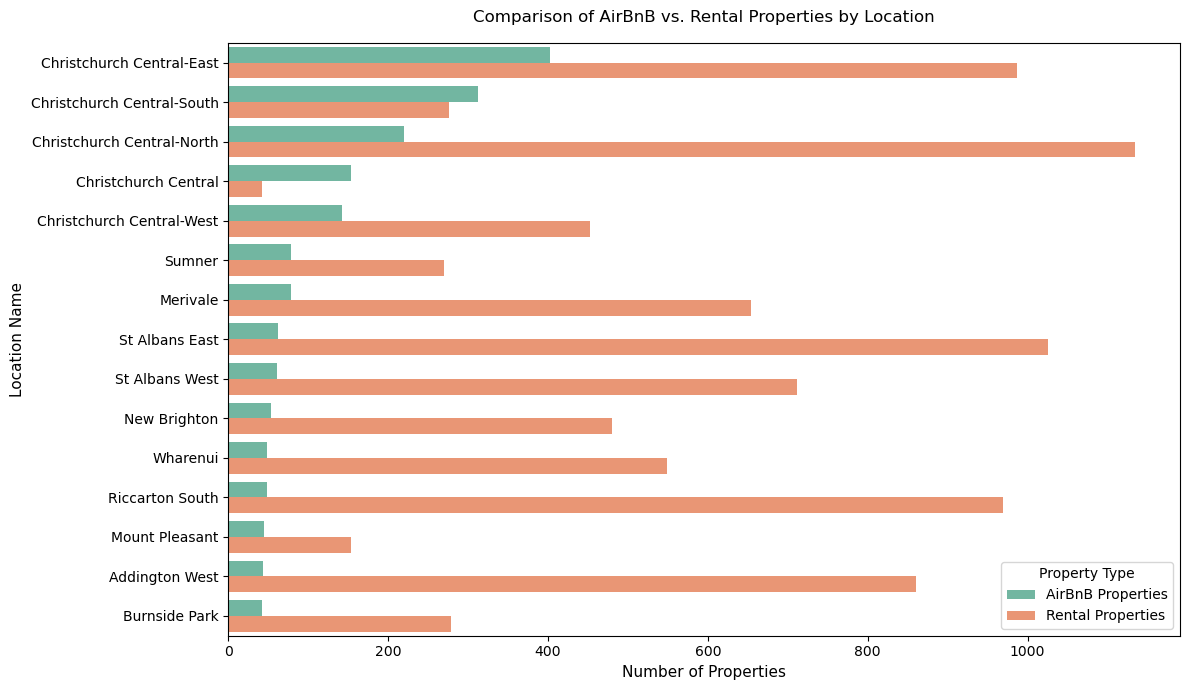

In [108]:
top_15 = location_counts.head(15)
df_melted = top_15.melt(
    id_vars="location_name",
    value_vars=["airbnb_property_count", "rental_property_count"],
    var_name="Property Type",
    value_name="Count",
)

df_melted["Property Type"] = df_melted["Property Type"].map(
    {
        "airbnb_property_count": "AirBnB Properties",
        "rental_property_count": "Rental Properties",
    }
)

# Plot clean side-by-side bar chart
plt.figure(figsize=(12, 7))
sns.barplot(
    data=df_melted,
    x="Count",
    y="location_name",
    hue="Property Type",
    palette="Set2",
)

plt.title(
    "Comparison of AirBnB vs. Rental Properties by Location",
    fontsize=12,
    pad=15,
)
plt.xlabel("Number of Properties", fontsize=11)
plt.ylabel("Location Name", fontsize=11)
plt.legend(title="Property Type")
plt.tight_layout()
plt.show()

#### Findings:

* **Christchurch Central-South** and **Christchurch Central** stand out as areas where short-term AirBnB supply actively outpaces long-term active rental bonds (*e.g., 312 AirBnBs vs. 276 rental bonds in Central-South, and 153 AirBnBs vs. 42 rental bonds in Christchurch Central*).
* In suburban nodes like **St Albans East**, **Riccarton South**, **Addington West**, and **Christchurch Central-North**, long-term active rental bonds heavily dominate the market landscape, maintaining over 700 to 1,100 active bonds per suburb.
* `Dwelling Type == 'ALL'` and `Number Of Beds == 'ALL'` have been filterred out because those specific rows represent the pre-calculated total summary for each location. If the individual breakdowns were kept (like 1-bedroom apartments or 3-bedroom houses) alongside the ALL valued rows, we would be double and triple counting the same rental properties. Filtering ALL ensures that each suburb captures 100% of the active rental bonds without inflating the numbers.